<h1 style="
    font-family: 'Aptos Display';
    font-size: 38px;
    margin-top: 0;
    margin-bottom: 2px;
    line-height: 1.1;
">
Crestview Mall Customer Segmentation Analysis
</h1>


# Part 1: Business Understanding

## 1.1 Executive Summary



**Crestview Mall(a fictional business case)** currently relies on broad marketing campaigns without sufficient evidence to identify distinct customer groups or allocate marketing resources effectively. This analysis aims to support more targeted marketing decisions through statistical testing and customer segmentation.

Using a dataset of 200 customers, Welch's independent two-sample t-test was conducted to assess gender-based differences in mean Spending Scores, followed by K-Means clustering using Age, Annual Income and Spending Score.

**Key Findings:**

- **Gender-Based Marketing:** Welch's t-test found no statistically significant difference in mean Spending Scores between male and female customers (p = 0.422), providing insufficient evidence to justify gender-based targeting alone.
- **Customer Segmentation:** K-Means identified six interpretable customer segments with different age, income and Spending Score profiles, providing a basis for differentiated marketing approaches.
- **Marketing Opportunities:** Customers with similar income levels may have substantially different Spending Scores, indicating that marketing decisions could benefit from considering multiple customer characteristics.

**Business Recommendations:**

Crestview Mall should explore segment-specific promotional campaigns rather than relying on broad advertising or gender-based assumptions. Marketing resources could be prioritised through small-scale trials, with campaign response rates, conversion rates and return on marketing investment used to evaluate effectiveness.


**Limitations and Data Improvements Required:**

The analysis is based on 200 customer records with limited demographic and Spending Score information. The absence of actual transaction values, purchase frequency, product preferences and campaign response data restricts deeper analysis of customer purchasing behaviour and marketing effectiveness.

Future improvements should focus on expanding the customer dataset, collecting reliable purchasing and campaign performance data, and enhancing customer profiles to support more precise segmentation and predictive analytics. The proposed marketing strategies should be validated through controlled campaign trials before wider implementation.


## 1.2 Background, Business Problem and Objective and Analysis Scope


**Introduction** 

Crestview Mall has traditionally relied on broad advertising campaigns targeting customers with different needs and spending behaviours. However, this approach may result in inefficient use of marketing resources because the shopping centre has limited evidence about which customer groups would benefit from different promotional offers.

To support a transition towards data-driven marketing, the management team seeks to better understand its customer base. The Marketing Director also believes that male and female customers have fundamentally different Spending Scores, although this assumption has not yet been statistically tested.

This project combines statistical hypothesis testing and unsupervised machine learning to examine spending patterns and explore potential customer segments. The findings will provide an evidence base for more informed marketing decisions.

**Business Problem** 

The key business challenge is Crestview Mall's lack of an evidence-based approach to identifying customer groups and allocating marketing resources effectively.

Without reliable insights into customer characteristics and spending patterns, the shopping centre may continue to implement generic campaigns that do not adequately address the needs of different customer groups.

Furthermore, the Marketing Director's assumption that male and female customers have different spending behaviours could influence marketing decisions without sufficient statistical evidence.

Crestview Mall therefore needs a more reliable understanding of its customer base to reduce reliance on subjective assumptions and support more appropriate targeting strategies.

**Business Objective** 

The primary business objective is to improve the relevance and efficiency of marketing campaigns through evidence-based customer segmentation and better-informed resource allocation.

Specifically, Crestview Mall aims to:

- **1. Assess whether gender-based differences in Spending Score provide meaningful evidence for marketing decisions.**
- **2. Identify potential customer segments that could benefit from differentiated promotional strategies.**
- **3. Develop a clearer understanding of customer characteristics and spending patterns if data is sufficient.**


**Key Areas of Analysis**

To support Crestview Mall's transition towards targeted marketing, the analysis will focus on two key areas:

| Key Area | Rationale for Investigation |
|----------|-----------------------------|
| **1. Gender and Spending Behaviour (Statistical Significance Testing)** | The Marketing Director believes that male and female customers have different spending behaviours. Statistical hypothesis testing will assess whether the difference in their average Spending Scores is statistically significant. The analysis will also consider the magnitude of any observed difference to determine its potential relevance to marketing decisions. |
| **2. Customer Segmentation (Unsupervised Learning)** | Crestview Mall lacks a clear understanding of its different customer groups. K-Means clustering will be applied to selected customer characteristics, including Age, Annual Income and Spending Score, to explore potential customer segments. The resulting clusters will be evaluated using appropriate validation metrics and interpreted according to their practical relevance to targeted marketing strategies. |


# Part 2: Data Understanding

## 2.1 Data Extraction

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Data Extraction

import pandas as pd
from pathlib import Path

# Relative path to the dataset
DATA_FILE = Path("Mall_Customers.csv")

# Verify that the dataset exists
if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

# Load dataset
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")

display(df.head())


Dataset loaded successfully.
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2.2 Data Inspection

In [3]:
# Step1 Inspect dataset structure

print("Dataset dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

Dataset dimensions:
Rows: 200
Columns: 5

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

First five records:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Last five records:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


## 2.3 Data Validation

In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records and customer IDs
print("\nDuplicate records:", df.duplicated().sum())
print("Duplicate Customer IDs:", df["CustomerID"].duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check categorical values and numerical ranges
print("\nGender categories:")
print(df["Gender"].value_counts())

print("\nNumerical ranges:")
print(df[["Age", "Annual Income (k$)",
          "Spending Score (1-100)"]].agg(["min", "max"]))


Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate records: 0
Duplicate Customer IDs: 0

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Gender categories:
Gender
Female    112
Male       88
Name: count, dtype: int64

Numerical ranges:
     Age  Annual Income (k$)  Spending Score (1-100)
min   18                  15                       1
max   70                 137                      99



<div style="color:#0D47A1;">

<strong>Key Findings:</strong>

- The dataset contains 200 customer records across five attributes.
- No missing values, duplicate records or duplicate Customer IDs were identified.
- All columns have appropriate data types.
- Gender contains two categories: Female (112) and Male (88).
- Age, Annual Income and Spending Score fall within plausible ranges.
- **No data cleaning is required based on these initial validation checks**.

</div>


## 2.4 Exploratory Data Analysis (EDA)


Exploratory Data Analysis (EDA) will be conducted to understand customer characteristics, examine spending patterns and explore potential relationships between variables. The analysis will focus on four areas:

1. **Descriptive Statistics:** Summarise the key numerical features, including Age, Annual Income and Spending Score, to understand their central tendencies and variability.

2. **Univariate Analysis:** Examine the distributions of individual numerical features and identify potential outliers using histograms and boxplots.

3. **Gender and Spending Score:** Compare the Spending Scores of male and female customers to explore potential differences and provide preliminary evidence for subsequent statistical hypothesis testing.

4. **Bivariate Analysis:** Investigate relationships between Age, Annual Income and Spending Score using scatter plots and correlation analysis to explore potential patterns relevant to customer segmentation.

The findings will provide a foundation for statistical hypothesis testing and subsequent K-Means clustering.


### 2.4.1 Descriptive Statistics

In [5]:

# Descriptive Statistics

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

display(df[features].describe().round(2))


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00



<div style="color:#0D47A1;">

<strong>Key Findings:</strong>

- The dataset contains 200 customers with ages ranging from 18 to 70 years.
- Average annual income is 60.56k, with a median of 61.50k.
- The average Spending Score is 50.20, indicating a moderate overall score.
- Spending Scores vary substantially across customers, suggesting potential differences in spending behaviour.

</div>


### 2.4.2 Univariate Analysis

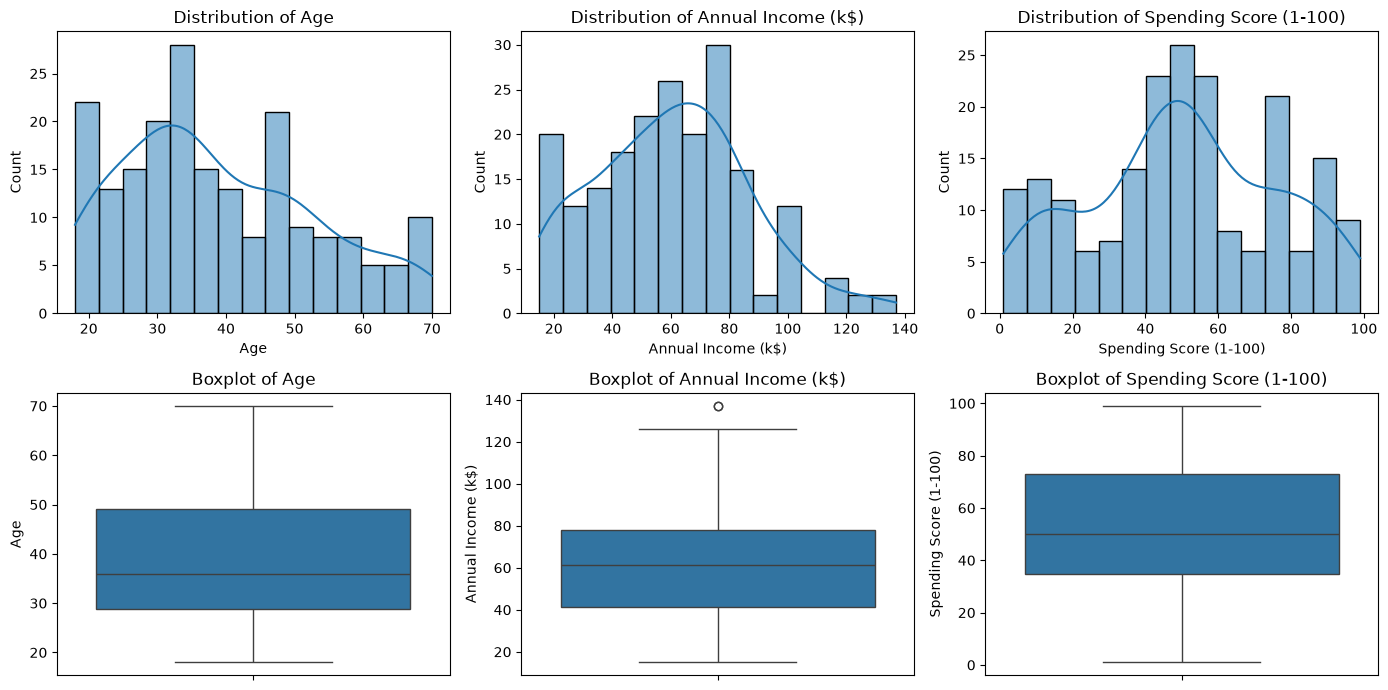

In [6]:

# Univariate Analysis

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for i, feature in enumerate(features):
    sns.histplot(data=df, x=feature, bins=15, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {feature}")

    sns.boxplot(data=df, y=feature, ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot of {feature}")

plt.tight_layout()
plt.show()



<div style="color:#0D47A1;">

<strong>Key Findings:</strong>

- **Age:** Customer ages range from 18 to 70, with a higher concentration of younger and middle-aged customers. No apparent outliers are identified.

- **Annual Income:** Income is concentrated around 40k–80k, with a slightly right-skewed distribution. Two potential outliers are identified at approximately $137k each.

- **Spending Score:** Spending Scores are widely distributed from 1 to 99, indicating substantial variation in customer spending behaviour. No apparent outliers are identified.

- **Implication for Clustering:** The three features have different numerical scales, making feature standardisation important before applying K-Means. The potential income outlier should also be considered because K-Means is sensitive to extreme values.

</div>


### 2.4.3 Gender and Spending Score

,count,mean,median,std
Gender,,,,
Female,112,51.53,50.0,24.11
Male,88,48.51,50.0,27.90


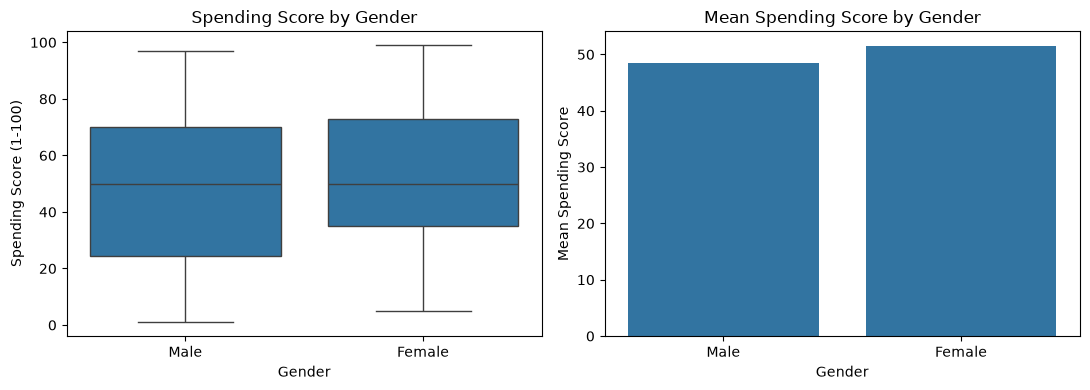

In [7]:

# Gender and Spending Score

gender_summary = df.groupby("Gender")["Spending Score (1-100)"].agg(
    ["count", "mean", "median", "std"]
).round(2)

display(gender_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(
    data=df, x="Gender", y="Spending Score (1-100)", ax=axes[0]
)
axes[0].set_title("Spending Score by Gender")

sns.barplot(
    data=df, x="Gender", y="Spending Score (1-100)",
    errorbar=None, ax=axes[1]
)
axes[1].set_title("Mean Spending Score by Gender")
axes[1].set_ylabel("Mean Spending Score")

plt.tight_layout()
plt.show()



<div style="color:#0D47A1;">

<strong>Key Findings:</strong>

- Female customers have a slightly higher average Spending Score (51.53) than male customers (48.51).
- The difference between the two group means is approximately 3.02 points.
- Both groups have the same median Spending Score of 50.
- Descriptive results alone cannot establish whether the observed difference is statistically significant. **Further hypothesis testing is required**.

</div>


### 2.4.4 Bivariate Analysis

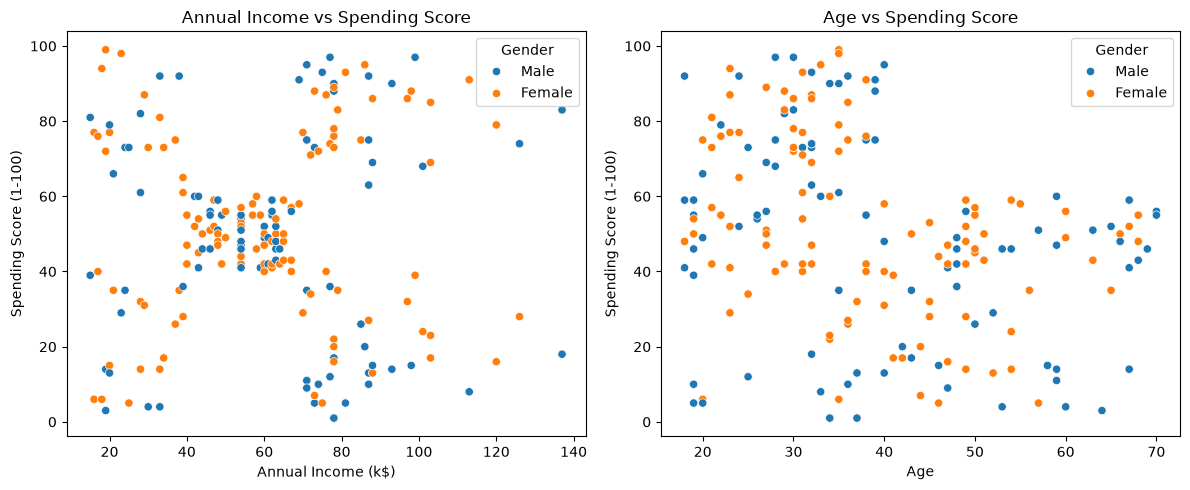

Pearson Correlation Matrix (r):


,Age,Annual Income (k$),Spending Score (1-100)
Age,1.000,-0.012,-0.327
Annual Income (k$),-0.012,1.000,0.010
Spending Score (1-100),-0.327,0.010,1.000


In [8]:

# Bivariate Analysis

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    ax=axes[0]
)
axes[0].set_title("Annual Income vs Spending Score")

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending Score (1-100)",
    hue="Gender",
    ax=axes[1]
)
axes[1].set_title("Age vs Spending Score")

plt.tight_layout()
plt.show()

# Correlation matrix
print("Pearson Correlation Matrix (r):")
display(df[features].corr(method="pearson").round(3))



<div style="color:#0D47A1;">

<strong>Key Findings:</strong>

- **Pearson Correlation Coefficient (r)** measures the strength and direction of a linear relationship between two numerical variables.

- **Annual Income vs Spending Score:** Almost no linear correlation is observed (r = 0.010), although the scatter plot suggests potential customer groupings.

- **Age vs Spending Score:** A moderate negative correlation (r = -0.327) suggests that younger customers generally tend to have higher Spending Scores.

- **Age vs Annual Income:** Almost no linear correlation is identified (r = -0.012).

- **Implication for Clustering:** The absence of strong linear correlations suggests that the three features may provide complementary information for customer segmentation. **The potential groupings will be further evaluated using K-Means clustering**.

</div>



# Part 3: Data Cleaning & Preparation


- The Crestview Mall dataset will be prepared for **statistical significance testing and unsupervised clustering**, based on the findings from Data Validation and Exploratory Data Analysis.
- The original dataset will remain unchanged to preserve data integrity. Separate working datasets will be maintained for statistical analysis and machine learning.

- The data preparation process includes:

    1. **Create Working Copies and Data Cleaning:** Create independent working copies and review whether any cleaning is required based on the validation results.
    2. **Outlier Assessment:** Assess the potential Annual Income outliers and determine whether they should be retained for analysis.
    3. **Feature Selection:** Select Age, Annual Income and Spending Score for clustering while excluding CustomerID and Gender.
    4. **Feature Scaling:** Standardise the three numerical features using StandardScaler to ensure comparable scales for K-Means.
    5. **Prepare Clustering Inputs:** Verify the scaled dataset containing 200 customer records and three numerical features.
    6. **Prepare Data for Significance Testing:** Retain Gender and the original Spending Score values for comparing the two customer groups.

<p> 
&nbsp;&nbsp;<strong>Gender</strong> will be excluded from clustering inputs but retained separately for statistical hypothesis testing in Part 4.</p>


## 3.1 Create working copies for data cleaning and preparation

**All transformations will be performed on working copies without modifying the original dataset.**

In [9]:

# Create Working Copy

# Preserve the original dataset
df_prepared = df.copy(deep=True)

# Verify the working copy
print("Original dataset shape:", df.shape)
print("Working copy shape:", df_prepared.shape)

print("\nWorking copy created successfully.")


Original dataset shape: (200, 5)
Working copy shape: (200, 5)

Working copy created successfully.


## 3.2 No Data Cleaning


Based on the findings from Section 2.3 Data Validation, no missing values, duplicate records or invalid data types were identified. Therefore, **no data cleaning is required** at this stage.

All 200 customer records and five attributes will be retained in the working dataset (`df_prepared`), while the original dataset remains unchanged.


## 3.3 Outlier Assessment

In [10]:

# Identify potential outliers using the IQR method
income = df_prepared["Annual Income (k$)"]

Q1 = income.quantile(0.25)
Q3 = income.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_prepared[
    (income < lower_bound) | (income > upper_bound)
]

print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"Potential outliers: {len(outliers)}")

display(outliers)



Lower bound: -13.25
Upper bound: 132.75
Potential outliers: 2


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83



<div style="color:#0D47A1;">

<strong>Key Findings:</strong>

- The IQR method identified two potential outlier records in Annual Income, both with values of $137k.
- These values represent plausible high-income customers rather than confirmed data errors.
- Removing these records could exclude a potentially valuable customer segment.
- **Decision:** Retain both records for subsequent clustering analysis, while recognising that extreme values may influence K-Means centroids.

</div>

## 3.4 Feature Selection



Three numerical features are selected for K-Means clustering: **Age, Annual Income (k$) and Spending Score (1-100)**. These variables represent customer demographics, financial characteristics and spending behaviour.

**CustomerID** is excluded because it is a unique identifier rather than a meaningful clustering feature.

**Gender** is excluded because it is a categorical variable that requires encoding to participate in the distance-based K-Means algorithm. The model focuses on numerical characteristics relevant to customer segmentation, while Gender is retained separately for statistical hypothesis testing in Part 4.

The selected features will be stored in a separate DataFrame to preserve the original dataset and the prepared working copy.



In [11]:

# Feature Selection

# Select numerical features for clustering
cluster_features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# Create clustering dataset
X = df_prepared[cluster_features].copy()

# Verify selected features
print("Selected clustering features:", X.columns.tolist())
print("Clustering dataset shape:", X.shape)

display(X.head())


Selected clustering features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Clustering dataset shape: (200, 3)


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


## 3.5 Feature Scaling



K-Means clustering is a distance-based algorithm. Since Age, Annual Income and Spending Score have different numerical scales, features with larger ranges may disproportionately influence the clustering results.

**StandardScaler** is applied to standardise the three selected features to a mean of approximately 0 and a standard deviation of approximately 1.

The scaled dataset will be used for K-Means clustering, while the original feature values will be preserved for subsequent cluster profiling and business interpretation.

**PCA is not applied**, as the dataset contains only three relevant numerical features, with no strong linear correlations identified during EDA. Retaining all three features also supports clearer interpretation of the customer segments.



In [12]:

# Feature Scaling

from sklearn.preprocessing import StandardScaler

# Initialise and apply StandardScaler
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Verify scaling results
print("Scaled dataset shape:", X_scaled.shape)

display(X_scaled.head())

print("\nScaled Feature Summary:")
display(X_scaled.agg(["mean", "std"]).round(3))


Scaled dataset shape: (200, 3)


,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980



Scaled Feature Summary:


,Age,Annual Income (k$),Spending Score (1-100)
mean,-0.000,-0.000,-0.000
std,1.003,1.003,1.003


## 3.6 Prepare Clustering Inputs



The standardised dataset from Section 3.5 will be used to prepare the final input for K-Means clustering.


The clustering input contains three numerical features: **Age, Annual Income and Spending Score**. **CustomerID and Gender are excluded**, as determined during Feature Selection in [Section 3.4](#3.4-Feature-Selection).


The final dataset will be checked for completeness, numerical data types and infinite values to confirm its suitability for K-Means clustering.


In [13]:

# Prepare Clustering Inputs

import numpy as np

# Create final clustering input
X_cluster = X_scaled.copy(deep=True)

# Validate clustering input
print("Clustering Input Validation")
print("Dataset shape:", X_cluster.shape)
print("Features:", X_cluster.columns.tolist())
print("All numerical:", all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in X_cluster.dtypes
))
print("Missing values:", X_cluster.isnull().sum().sum())
print("Infinite values:", np.isinf(X_cluster.to_numpy()).sum())

print("\nClustering input prepared successfully.")



Clustering Input Validation
Dataset shape: (200, 3)
Features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
All numerical: True
Missing values: 0
Infinite values: 0

Clustering input prepared successfully.


## 3.7 Prepare Data for Significance Testing



A separate statistical analysis dataset will be prepared using **Gender** and **Spending Score (1-100)** to examine potential differences in mean Spending Scores between male and female customers.

The original Spending Score values will be retained without standardisation to ensure that the statistical results can be interpreted on the original scale.

The dataset will be checked for completeness, appropriate data types and representation of both gender groups before hypothesis testing.


In [14]:

# Prepare Data for Significance Testing

# Create statistical analysis dataset
df_stats = df_prepared[
    ["Gender", "Spending Score (1-100)"]
].copy(deep=True)

# Validate statistical analysis inputs
print("Statistical Analysis Input Validation")
print("Dataset shape:", df_stats.shape)
print("Missing values:", df_stats.isnull().sum().sum())
print("Gender categories:", df_stats["Gender"].unique().tolist())
print("Spending Score numerical:",
      pd.api.types.is_numeric_dtype(df_stats["Spending Score (1-100)"]))

print("\nSample size by Gender:")
print(df_stats["Gender"].value_counts())

print("\nSpending Score range:")
print("Minimum:", df_stats["Spending Score (1-100)"].min())
print("Maximum:", df_stats["Spending Score (1-100)"].max())

print("\nStatistical analysis input prepared successfully.")


Statistical Analysis Input Validation
Dataset shape: (200, 2)
Missing values: 0
Gender categories: ['Male', 'Female']
Spending Score numerical: True

Sample size by Gender:
Gender
Female    112
Male       88
Name: count, dtype: int64

Spending Score range:
Minimum: 1
Maximum: 99

Statistical analysis input prepared successfully.


# Part 4: Significance Testing

## 4.1 Define Research Question and Hypotheses



| Planning Item | Description |
|---|---|
| **Business Focus** | Investigate whether male and female customers at Crestview Mall have different mean Spending Scores to assess the Marketing Director's assumption and inform marketing decisions. |
| **Research Question** | Is there a statistically significant difference in mean Spending Score between male and female customers? |
| **H₀ (Null Hypothesis)** | $\mu_{\text{Male}} = \mu_{\text{Female}}$ |
| **H₁ (Alternative Hypothesis)** | $\mu_{\text{Male}} \neq \mu_{\text{Female}}$ |
| **Statistical Method** | Welch's Independent Two-Sample t-test |
| **Significance Level** | $\alpha = 0.05$, two-tailed |
| **Planned Outputs** | Descriptive statistics, t-statistic, degrees of freedom, p-value, 95% confidence interval and Cohen's d. |


## 4.2 Assessment of Welch's t-test Assumptions




Before conducting Welch's independent two-sample t-test, the relevant statistical assumptions will be assessed to determine whether the test is appropriate for comparing mean Spending Scores between male and female customers.

The assessment will consider **independence of observations, normality, potential extreme outliers and variance requirements**. Findings from previous data validation and EDA ([Section 2.4.3](#2.4.3-Gender-and-Spending-Score)）will be used alongside Q-Q plots to evaluate the suitability of the test.


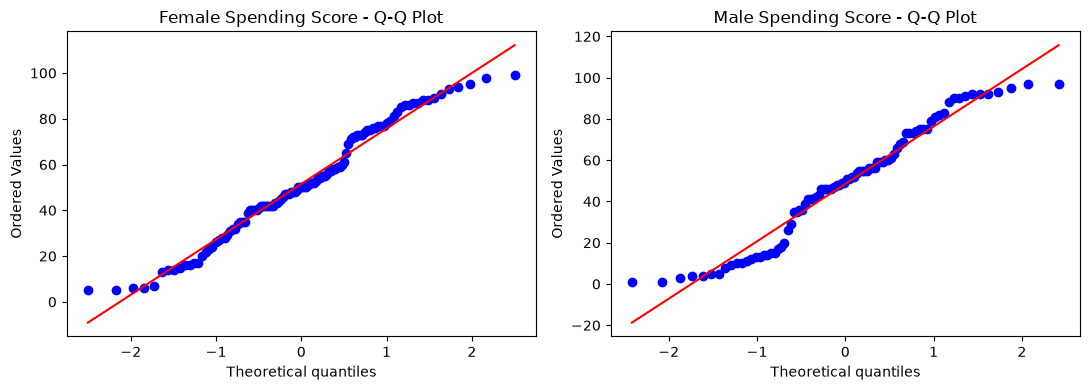

In [15]:

# Check Statistical Assumptions

import matplotlib.pyplot as plt
from scipy import stats

# Separate Spending Scores by gender
female_scores = df_stats.loc[
    df_stats["Gender"] == "Female", "Spending Score (1-100)"
]

male_scores = df_stats.loc[
    df_stats["Gender"] == "Male", "Spending Score (1-100)"
]

# Q-Q plots for normality assessment
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(female_scores, dist="norm", plot=axes[0])
axes[0].set_title("Female Spending Score - Q-Q Plot")

stats.probplot(male_scores, dist="norm", plot=axes[1])
axes[1].set_title("Male Spending Score - Q-Q Plot")

plt.tight_layout()
plt.show()


**Key Findings**

The suitability of Welch's independent two-sample t-test is evaluated against the following statistical assumptions and assessment criteria.

| Assumption | Assessment Criterion | Crestview Mall Evidence | Assessment |
|---|---|---|---|
| **Numerical Dependent Variable** | The dependent variable must be numerical. | Spending Score (1–100) is numerical. | Satisfied |
| **Independent Groups** | Two distinct, non-overlapping groups are required. | Male (n = 88) and Female (n = 112). | Satisfied |
| **Independent Observations** | Observations should be independent within and between groups. | Each customer has a unique ID, but sampling independence cannot be fully verified. | Assumed |
| **Normality** | Approximately normal distributions or sufficiently reliable mean-based inference with adequate sample sizes. | Q-Q plots show departures from normality. Both groups exceed the commonly used reference of n ≥ 30. | Acceptable with caution |
| **Extreme Outliers** | No extreme observations that seriously distort group means or variances. | Spending Scores are bounded between 1 and 100; severe influential outliers have not been independently established. | Not fully assessed |
| **Equality of Variances** | Not required for Welch's t-test. | Unequal population variances are permitted. | Not required |

**Conclusion:**

Welch's independent two-sample t-test is considered appropriate for comparing mean Spending Scores between male and female customers. Although the Q-Q plots indicate departures from normality, both groups have relatively large sample sizes, supporting the robustness of the test to moderate non-normality.

Equal population variances are not required. The analysis proceeds under the assumption of independent observations, while recognising that sampling independence and the influence of extreme values cannot be fully verified from the available evidence.


## 4.3 Perform Welch's Independent Two-Sample t-test


Welch's independent two-sample t-test is conducted to determine whether the mean Spending Score differs significantly between male and female customers.

The test uses a **two-tailed significance level of α = 0.05** and does not assume equal population variances.

The results will include the t-statistic, degrees of freedom, p-value, mean difference, 95% confidence interval and Cohen's d to assess both statistical significance and the magnitude of the observed difference.


In [16]:

# Welch's Independent Two-Sample t-test

import numpy as np
from scipy import stats

# Set significance level
alpha = 0.05

# Separate Spending Scores by gender
male = df_stats.loc[
    df_stats["Gender"] == "Male", "Spending Score (1-100)"
]

female = df_stats.loc[
    df_stats["Gender"] == "Female", "Spending Score (1-100)"
]

# Perform Welch's two-tailed t-test
result = stats.ttest_ind(
    male, female,
    equal_var=False,
    alternative="two-sided"
)

# Calculate the mean difference and standard error
mean_diff = male.mean() - female.mean()

v1 = male.var(ddof=1) / len(male)
v2 = female.var(ddof=1) / len(female)
se = np.sqrt(v1 + v2)

# Calculate Welch-Satterthwaite degrees of freedom
df_welch = (v1 + v2)**2 / (
    v1**2 / (len(male) - 1)
    + v2**2 / (len(female) - 1)
)

# Calculate 95% confidence interval
ci_lower, ci_upper = stats.t.interval(
    0.95, df_welch, loc=mean_diff, scale=se
)

# Calculate Cohen's d
pooled_sd = np.sqrt(
    ((len(male) - 1) * male.var(ddof=1)
     + (len(female) - 1) * female.var(ddof=1))
    / (len(male) + len(female) - 2)
)

cohens_d = mean_diff / pooled_sd


# Display Welch's t-test results in a summary table

results_table = pd.DataFrame({
    "Statistic": [
        "Mean Difference (Male - Female)",
        "t-statistic",
        "Welch Degrees of Freedom",
        "p-value",
        "95% CI Lower",
        "95% CI Upper",
        "Cohen's d",
        "Significance Level (α)"
    ],
    "Value": [
        mean_diff,
        result.statistic,
        df_welch,
        result.pvalue,
        ci_lower,
        ci_upper,
        cohens_d,
        alpha
    ]
})

print("Welch's Independent Two-Sample t-test - Spending Score")
display(results_table.style.format({"Value": "{:.4f}"}))

# Hypothesis decision
if result.pvalue < alpha:
    print("\nDecision: Reject H0")
    print("Result: Statistically significant difference in mean Spending Score.")
else:
    print("\nDecision: Fail to reject H0")
    print("Result: No statistically significant difference in mean Spending Score.")


Welch's Independent Two-Sample t-test - Spending Score


,Statistic,Value
0,Mean Difference (Male - Female),-3.0154
1,t-statistic,-0.8049
2,Welch Degrees of Freedom,172.5341
3,p-value,0.4220
4,95% CI Lower,-10.4102
5,95% CI Upper,4.3793
6,Cohen's d,-0.1167
7,Significance Level (α),0.0500



Decision: Fail to reject H0
Result: No statistically significant difference in mean Spending Score.


## 4.4 Interpret Results and Business Implications


**Statistical Interpretation**

Welch's independent two-sample t-test found no statistically significant difference in mean Spending Score between male and female customers.

| Statistical Measure | Result | Interpretation |
|---|---|---|
| **Mean Difference (Male − Female)** | -3.02 | Female customers have a slightly higher average Spending Score than male customers. |
| **p-value** | 0.422 | Exceeds the significance level of 0.05, indicating insufficient evidence to reject H₀. |
| **95% Confidence Interval** | [-10.41, 4.38] | Includes zero, indicating that the population mean difference could be zero. |
| **Cohen's d** | -0.117 | Indicates a very small observed standardised difference between the two groups. |
| **Hypothesis Decision** | Fail to reject H₀ | There is insufficient statistical evidence to conclude that the population mean Spending Scores differ by gender. |

The results do not establish that male and female customers have identical spending behaviour. Rather, the available sample does not provide sufficient evidence of a difference in their population mean Spending Scores.

**Business Implications**

The findings do not support the Marketing Director's assumption that male and female customers have fundamentally different mean Spending Scores.

- **Gender-Based Targeting:** The statistical evidence does not justify using gender alone as the basis for differentiated marketing campaigns.

- **Marketing Resource Allocation:** Crestview Mall should not rely on gender alone when developing targeted marketing strategies.
- **Data-Driven Customer Segmentation:** As gender alone does not demonstrate a statistically significant difference in mean Spending Score, further analysis is needed to identify potentially meaningful customer groups.


# Part 5: Unsupervised Clustering



**K-Means clustering is selected to identify customer segments** based on Age, Annual Income and Spending Score, providing a straightforward and interpretable approach suitable for this dataset of 200 customers.

**Further model refinement is not pursued** because the dataset contains only three numerical clustering features, making PCA unnecessary for dimensionality reduction, while additional model complexity is not justified by the exploratory objectives of this analysis.




## 5.1 Clustering Objectives and Approach



Following the statistical hypothesis testing in Part 4, K-Means clustering will be applied to explore potential customer segments based on Age, Annual Income and Spending Score.

Unlike significance testing, which examines differences between predefined groups, **unsupervised clustering identifies groups of customers with similar characteristics without predefined cluster labels**.

The objective is to identify, evaluate and interpret potential customer segments to support more targeted, evidence-based marketing strategies.


| Planning Item | Description |
|---|---|
| **Business Focus** | Identify customer groups with distinct demographic, financial and spending profiles to support targeted marketing decisions. |
| **Clustering Objective** | Explore meaningful customer segments based on similarities in Age, Annual Income and Spending Score. |
| **Machine Learning Method** | Unsupervised Learning — K-Means Clustering. |
| **Input Dataset** | `X_cluster`: 200 customer records with three standardised numerical features. |
| **Feature Selection** | Age, Annual Income (k$) and Spending Score (1-100). |
| **Preprocessing** | StandardScaler applied in [Section 3.5](#3.5-Feature-Scaling), with clustering inputs prepared and validated in [Section 3.6](#3.6-Prepare-Clustering-Inputs). |
| **Cluster Number Selection** | Evaluate candidate values of K using the Elbow Method and Silhouette Score, supported by Davies–Bouldin Index and Calinski–Harabasz Score. |
| **Model Evaluation** | Assess cluster compactness, separation and overall clustering quality. |
| **Cluster Profiling** | Examine the original Age, Annual Income and Spending Score values to identify and interpret the characteristics of each customer segment. |
| **Expected Business Output** | Develop interpretable customer profiles and recommend potential targeted marketing strategies for different segments. |


## 5.2 K-Means Clustering



K-Means clustering requires the number of clusters (K) to be specified before model training. To identify a suitable K, multiple clustering solutions will be evaluated using the standardised dataset prepared in Part 3.

Four evaluation metrics will be used:

| Evaluation Metric | Purpose | Selection Criterion |
|---|---|---|
| **Elbow Method (Inertia)** | Measures within-cluster variation and compactness. | Identify the point where further increases in K provide diminishing improvements. |
| **Silhouette Score** | Measures how well customers fit within their assigned clusters compared with neighbouring clusters. | Higher is better. |
| **Davies–Bouldin Index (DBI)** | Evaluates cluster separation relative to within-cluster dispersion. | Lower is better. |
| **Calinski–Harabasz Score (CH)** | Measures between-cluster separation relative to within-cluster dispersion. | Higher is better. |

Candidate values of K from **2 to 10** will be evaluated using the same standardised features.

The final number of clusters will be selected by considering the evaluation metrics together with cluster sizes and business interpretability, rather than relying on a single metric.


### 5.2.1 Determine the Number of Clusters

K-Means Clustering Evaluation (K = 2 to 10)


,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,2,389.386,0.335,1.261,107.096
1,3,295.212,0.358,1.050,101.695
2,4,205.225,0.404,0.931,125.676
3,5,168.248,0.417,0.875,125.101
4,6,133.868,0.427,0.828,135.102
5,7,117.012,0.417,0.793,132.774
6,8,103.829,0.409,0.889,131.074
7,9,92.349,0.420,0.854,131.242
8,10,81.987,0.397,0.906,133.385


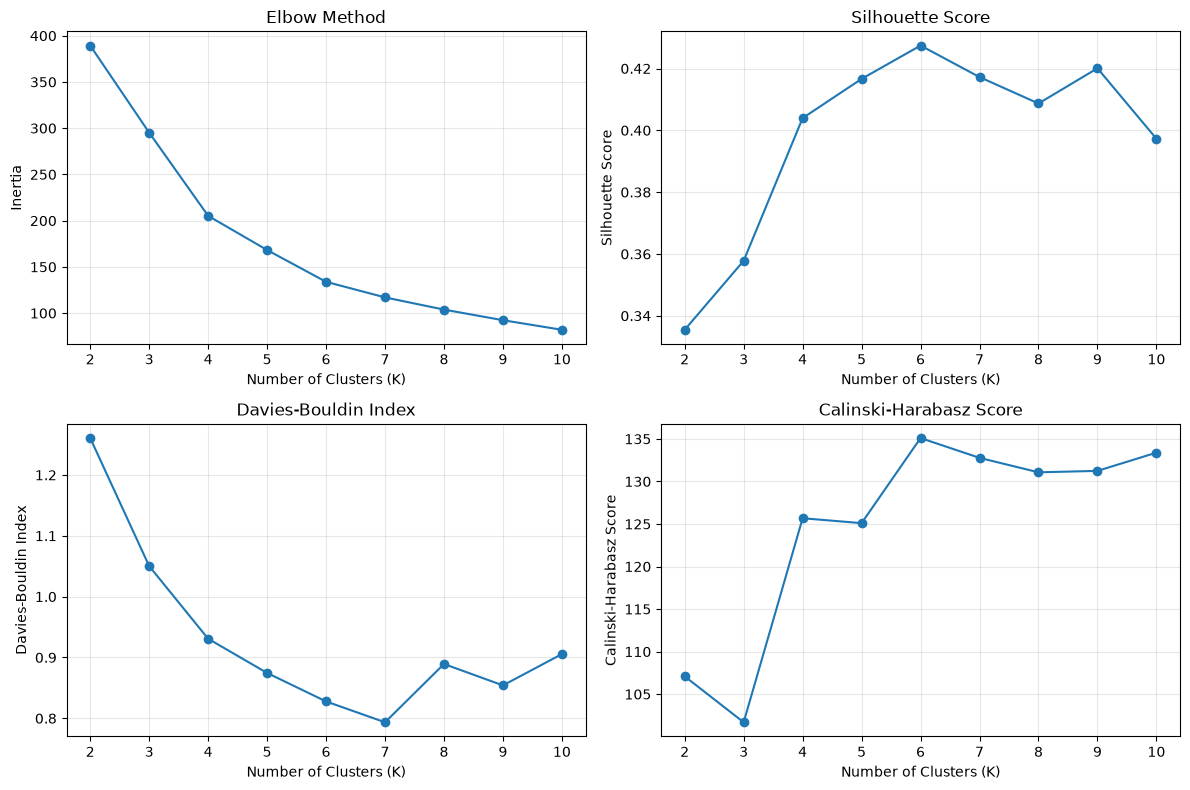

In [17]:

# Determine the Number of Clusters

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate candidate K values
k_range = range(2, 11)
results = []

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_cluster)

    results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette Score": silhouette_score(X_cluster, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_cluster, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_cluster, labels)
    })

# Display evaluation results
k_results = pd.DataFrame(results)

print("K-Means Clustering Evaluation (K = 2 to 10)")
display(k_results.round(3))


# Visualise K-Means evaluation metrics

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

metrics = [
    ("Inertia", "Elbow Method"),
    ("Silhouette Score", "Silhouette Score"),
    ("Davies-Bouldin Index", "Davies-Bouldin Index"),
    ("Calinski-Harabasz Score", "Calinski-Harabasz Score")
]

for ax, (metric, title) in zip(axes.flat, metrics):
    ax.plot(k_results["K"], k_results[metric], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Number of Clusters (K)")
    ax.set_ylabel(metric)
    ax.set_xticks(list(k_range))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Key Findings and Final Selection of K**

- **Elbow Method:** Inertia decreases as K increases, with diminishing improvements at higher K values, suggesting that additional clusters provide progressively smaller benefits.

- **Silhouette Score:** K = 6 achieves the highest score (0.427), indicating the best overall balance of cluster cohesion and separation among the evaluated solutions.

- **Davies–Bouldin Index (DBI):** K = 7 produces the lowest DBI (0.793), indicating favourable cluster compactness and separation.

- **Calinski–Harabasz Score (CH):** K = 6 achieves the highest CH score (135.1), indicating strong between-cluster separation relative to within-cluster dispersion.

**Final Decision: K = 6**

Although K = 7 achieves the lowest DBI, both the Silhouette Score and CH Score favour K = 6. The Elbow Method also indicates diminishing improvements as the number of clusters increases.

Considering the overall evaluation results, **K = 6 is selected as the preferred clustering solution**, providing a reasonable balance between clustering quality and model complexity.

The selected K will be used to develop the final K-Means model, followed by cluster profiling and business interpretation to assess the practical relevance of the identified customer segments.


### 5.2.2 Cluster Profiling and Customer Segmentation Analysis

In [18]:

# Clustering Profiling and Customer Segmentation Analysis

from sklearn.cluster import KMeans

# Fit the selected K-Means model
final_kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=20
)

cluster_labels = final_kmeans.fit_predict(X_cluster)

# Create a separate dataset for customer profiling
df_profile = df_prepared.loc[X_cluster.index].copy(deep=True)
df_profile["Cluster"] = cluster_labels

# Summarise customer characteristics by cluster
cluster_summary = df_profile.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Mean_Age=("Age", "mean"),
    Mean_Income=("Annual Income (k$)", "mean"),
    Mean_Spending_Score=("Spending Score (1-100)", "mean")
)

# Calculate customer percentage
cluster_summary["Percentage (%)"] = (
    cluster_summary["Customers"] / len(df_profile) * 100
)

print("K-Means Customer Segmentation — K = 6")
display(cluster_summary.round(2))

print("\nTotal customers:", cluster_summary["Customers"].sum())


K-Means Customer Segmentation — K = 6


,Customers,Mean_Age,Mean_Income,Mean_Spending_Score,Percentage (%)
Cluster,,,,,
0,33,41.94,88.94,16.97,16.5
1,45,56.33,54.27,49.07,22.5
2,24,25.25,25.83,76.92,12.0
3,39,32.69,86.54,82.13,19.5
4,38,26.68,57.58,47.79,19.0
5,21,45.52,26.29,19.38,10.5



Total customers: 200



**Customer Segment Profiles**

| Cluster | Customers | Percentage (%) | Customer Profile |
|---|---:|---:|---|
| **0** | 33 | 16.5% | Middle-Aged, High-Income, Low-Scoring |
| **1** | 45 | 22.5% | Older, Moderate-Income, Moderate-Scoring |
| **2** | 24 | 12.0% | Young, Low-Income, High-Scoring |
| **3** | 39 | 19.5% | Young Adult, High-Income, High-Scoring |
| **4** | 38 | 19.0% | Young, Moderate-Income, Moderate-Scoring |
| **5** | 21 | 10.5% | Middle-Aged, Low-Income, Low-Scoring |
| **Total** | **200** | **100.0%** | |

**Overall Finding:**

The six customer segments demonstrate different combinations of Age, Annual Income and Spending Score.

Clusters 0 and 3 have similarly high average incomes but substantially different Spending Scores, while Clusters 1 and 4 have similar income and spending profiles but differ considerably in age.

These findings highlight the importance of considering all three features when developing targeted customer segmentation strategies.



### 5.2.3 Customer Segment Visualisation

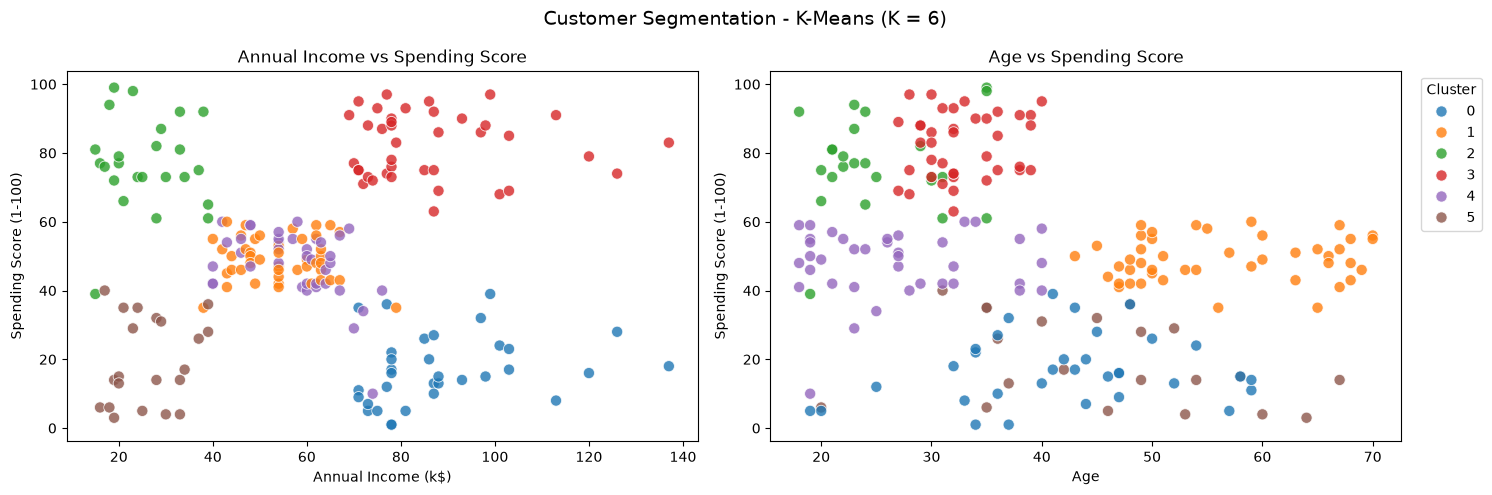

In [19]:

# Customer Segment Visualisation

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Annual Income vs Spending Score
sns.scatterplot(
    data=df_profile,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=65,
    alpha=0.8,
    ax=axes[0]
)

axes[0].set_title("Annual Income vs Spending Score")
axes[0].legend_.remove()

# Age vs Spending Score
sns.scatterplot(
    data=df_profile,
    x="Age",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=65,
    alpha=0.8,
    ax=axes[1]
)

axes[1].set_title("Age vs Spending Score")
axes[1].legend(
    title="Cluster",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig.suptitle("Customer Segmentation - K-Means (K = 6)", fontsize=14)

plt.tight_layout()
plt.show()



**Model Quality Evaluation**

The two scatter plots provide a visual assessment of the six customer segments identified by K-Means clustering.

| Evaluation Aspect | Observation | Assessment |
|---|---|---|
| **Cluster Cohesion** | Most customers within the same cluster show similar age, income and Spending Score patterns. | The clusters demonstrate reasonable cohesion, although some groups are more dispersed than others. |
| **Cluster Separation** | High- and low-Spending Score groups are relatively distinct, while some moderate-scoring clusters overlap in the Income vs Spending Score plot. | Separation varies across clusters. |
| **Feature Contribution** | Clusters 1 and 4 overlap in income and Spending Score but are differentiated by age. | All three features contribute to distinguishing customer segments. |
| **Cluster Overlap** | Some overlap is visible in both two-dimensional plots. | This does not necessarily indicate poor clustering because K-Means uses three standardised features. |


**Overall Model Quality Assessment:**

The K-Means model with **K = 6** produces six interpretable customer segments based on Age, Annual Income and Spending Score. The scatter plots reveal distinguishable customer profiles, while the overall clustering evaluation metrics from [Section 5.2.1](#5.2.1-Determine-the-Number-of-Clusters) indicate moderate clustering quality.

Although some overlap exists, the model provides a reasonable exploratory segmentation structure for further business interpretation. However, the effectiveness of these segments for targeted marketing will require validation using actual campaign performance data.


## 5.3 Business Interpretability and Marketing Opportunities



The six customer segments identified through K-Means clustering provide insights into different combinations of Age, Annual Income and Spending Score.

These profiles can be used to develop potential marketing strategies that are more relevant to each customer group, rather than applying generic campaigns across the entire customer base.

**Proposed Marketing Strategies by Customer Segment**

| Cluster | Customer Profile | Proposed Marketing Strategy | Business Rationale |
|---|---|---|---|
| **0** | Middle-Aged, High-Income, Low-Scoring | Trial personalised promotions and premium product offers. | Higher-income customers with low Spending Scores may represent an opportunity to investigate unmet shopping needs and encourage greater engagement. |
| **1** | Older, Moderate-Income, Moderate-Scoring | Offer loyalty rewards and targeted promotions across everyday shopping categories. | Loyalty incentives may encourage repeat visits and strengthen engagement among this relatively large customer segment. |
| **2** | Young, Low-Income, High-Scoring | Promote affordable products, student-oriented discounts and seasonal offers. | Younger customers with lower incomes but high Spending Scores may respond to value-focused campaigns that align with their financial profiles. |
| **3** | Young Adult, High-Income, High-Scoring | Trial premium loyalty benefits, exclusive offers and early access to promotions. | Customers with relatively high incomes and Spending Scores may be suitable candidates for premium engagement strategies. |
| **4** | Young, Moderate-Income, Moderate-Scoring | Promote lifestyle offers, seasonal campaigns and digital loyalty incentives. | Tailored promotions could help increase engagement among younger customers with moderate spending profiles. |
| **5** | Middle-Aged, Low-Income, Low-Scoring | Trial essential-product promotions and value-oriented offers. | Affordable promotions may help explore opportunities to improve engagement among customers with lower incomes and Spending Scores. |

**Marketing Priorities**

- **Customer Engagement:** Explore personalised promotions based on the characteristics of each customer segment.
- **Resource Allocation:** Use segment size and spending profiles to prioritise marketing trials rather than distributing resources equally across all customers.
- **Campaign Validation:** Measure campaign response rates, conversion rates and return on marketing investment to assess whether the proposed strategies are effective.

**Business Interpretation:**

The segmentation results suggest that customers with similar income levels may have substantially different Spending Scores, while customers with similar Spending Scores may differ considerably in age and income.

Therefore, Crestview Mall could benefit from developing differentiated marketing campaigns based on multiple customer characteristics rather than gender alone.

However, these recommendations are exploratory. The dataset does not contain actual purchasing transactions, product preferences or campaign response data. The effectiveness of the proposed strategies must therefore be validated through future marketing campaigns.


# Part 6: Conclusions and Limitations

## 6.1 Analysis Limitations



The analysis provides useful insights into customer spending behaviour and segmentation. However, several limitations should be considered when interpreting the findings.

- **Sample Size and Representativeness:** The dataset contains only 200 customer records. As the sampling method is unknown, the findings may not represent the broader customer population of Crestview Mall.

- **Limited Customer Information:** The analysis is restricted to Gender, Age, Annual Income and Spending Score. Other relevant factors, such as purchase history, shopping frequency, product preferences and transaction values, are unavailable.

- **Hypothesis Testing:** Welch's t-test did not identify a statistically significant difference in average Spending Scores between genders. However, this does not establish that male and female customers have identical spending behaviour. The validity of the statistical inference also depends on the sampling and independence assumptions.

- **K-Means Clustering:** K-Means requires a predefined number of clusters and is sensitive to feature selection and scaling. Some overlap between customer segments indicates that the identified groups should not be treated as perfectly distinct.

- **Business Validation:** Spending Score does not directly measure customer revenue or profitability. Furthermore, the proposed marketing strategies have not been tested against actual campaign outcomes, so their business effectiveness remains unverified.


## 6.2 Future Data Improvement and Predictive Development



To improve the reliability and business value of future customer analysis, Crestview Mall could consider the following developments.

| Development Area | Proposed Improvement | Expected Business Value |
|---|---|---|
| **Data Collection** | Collect additional customer data, including purchase frequency, transaction values, product categories and shopping history. | Provide a more comprehensive understanding of customer behaviour and spending patterns. |
| **Data Quality and Representativeness** | Expand the dataset and establish consistent data collection, validation and updating procedures. | Improve data reliability and support more representative customer analysis. |
| **Customer Segmentation** | Periodically review customer clusters using updated data and additional relevant features. | Maintain relevant customer profiles as shopping behaviour changes. |
| **Predictive Modelling** | Develop supervised learning models to predict outcomes such as campaign response, repeat purchases or future spending, once suitable historical target data becomes available. | Support proactive marketing decisions and more effective resource allocation. |
| **Model Validation** | Evaluate predictive models using appropriate performance metrics and validate marketing recommendations through controlled campaign trials. | Assess model reliability and measure actual business outcomes before wider implementation. |

**Future Development:**

The current K-Means model provides an exploratory foundation for understanding customer segments. With improved data collection and suitable historical outcomes, Crestview Mall could extend its analysis from **descriptive customer segmentation to predictive analytics**, supporting more personalised and evidence-based marketing decisions.


# References 



Choudhary, V. (n.d.). *Mall customer segmentation data* [Data set]. Kaggle. https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

SciPy Community. (n.d.). *scipy.stats.ttest_ind*. SciPy documentation. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

Scikit-learn developers. (n.d.). *KMeans*. Scikit-learn documentation. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

Scikit-learn developers. (n.d.). *StandardScaler*. Scikit-learn documentation. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

Scikit-learn developers. (n.d.). *Clustering performance evaluation*. Scikit-learn documentation. https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation

Scikit-learn developers. (n.d.). *Principal component analysis (PCA)*. Scikit-learn documentation. https://scikit-learn.org/stable/modules/decomposition.html#pca
